# Kelvin–Helmholtz instability with a 2D finite-volume Euler solver
**Astrophysical Fluid Dynamics: Assignment 2** · Aryana Haghjoo

This notebook runs and analyses the simulation:
1. the method, in brief
2. the initial conditions
3. **a movie** of the instability rolling up
4. snapshots, plus the effect of resolution and the slope limiter
5. a quantitative test: measured linear growth rate vs. theory
6. conservation checks

The solver lives in `kh_sim.py`, adapted from P. Mocz's tutorial ([github.com/pmocz/finitevolume-python](https://github.com/pmocz/finitevolume-python)). The expensive runs (up to $512^2$) were done once and saved in `results.pkl`. Section 5 can recompute them if you set `RECOMPUTE = True`.

In [1]:
import numpy as np, pickle, time
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Image, display
import kh_sim

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})
CMAP, VMIN, VMAX = 'magma', 0.8, 2.2
RECOMPUTE = False   # True: redo the N=64..512 runs (~25 min)

## 1. Method
The code solves the 2D compressible **Euler equations** in conservative form, for an ideal gas with $\gamma = 5/3$:

$$\partial_t \rho + \nabla\cdot(\rho\mathbf v)=0,\qquad
\partial_t(\rho\mathbf v)+\nabla\cdot(\rho\mathbf v\mathbf v + P\,\mathbf I)=0,\qquad
\partial_t E+\nabla\cdot\big[(E+P)\mathbf v\big]=0,$$

where $E = P/(\gamma-1)+\tfrac12\rho v^2$.

## 2. Initial conditions
A dense band ($\rho = 2$) moves to the right at $v_x = +0.5$ between $y = 0.25$ and $0.75$. Lighter gas ($\rho = 1$) moves left at $v_x = -0.5$. Pressure is uniform, $P = 2.5$, so the shear is subsonic (Mach 0.25–0.35). A small vertical velocity $v_y = w_0 \sin(4\pi x)$, localized at the two interfaces, seeds the instability with two wavelengths across the box.

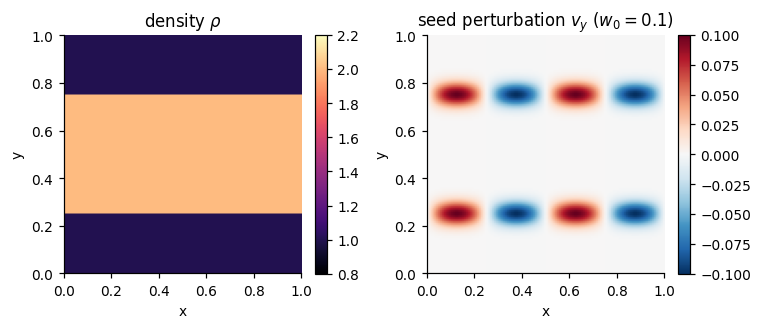

In [2]:
N = 128
dx = 1 / N
x = np.linspace(0.5*dx, 1-0.5*dx, N); Y, X = np.meshgrid(x, x)
sig = 0.05/np.sqrt(2)
rho0 = 1 + (np.abs(Y-0.5) < 0.25)
vy0 = 0.1*np.sin(4*np.pi*X)*(np.exp(-(Y-0.25)**2/(2*sig**2)) + np.exp(-(Y-0.75)**2/(2*sig**2)))

fig, ax = plt.subplots(1, 2, figsize=(7, 3))
im0 = ax[0].imshow(rho0.T, origin='lower', extent=[0,1,0,1], cmap=CMAP, vmin=VMIN, vmax=VMAX)
ax[0].set_title(r'density $\rho$'); fig.colorbar(im0, ax=ax[0], fraction=0.046)
im1 = ax[1].imshow(vy0.T, origin='lower', extent=[0,1,0,1], cmap='RdBu_r', vmin=-0.1, vmax=0.1)
ax[1].set_title(r'seed perturbation $v_y$ ($w_0=0.1$)'); fig.colorbar(im1, ax=ax[1], fraction=0.046)
for a in ax: a.set_xlabel('x'); a.set_ylabel('y')
plt.tight_layout(); plt.show()

## 3. Movie
This is the fiducial run: $N = 256^2$, $w_0 = 0.1$, with a frame every $\Delta t = 0.02$ up to $t = 2$. 

In [3]:
t0 = time.time()
frame_times = np.round(np.arange(0, 2.0001, 0.02), 10)
movie_run = kh_sim.run(N=256, tEnd=2.0, w0=0.1, snap_times=tuple(frame_times))
frames = [movie_run['snaps'][t] for t in sorted(movie_run['snaps'])]
print(f'{len(frames)} frames, {movie_run["nstep"]} time steps, {time.time()-t0:.0f} s')

101 frames, 3749 time steps, 16 s


In [4]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
im = ax.imshow(frames[0].T, origin='lower', extent=[0,1,0,1], cmap=CMAP, vmin=VMIN, vmax=VMAX)
ax.set_xticks([]); ax.set_yticks([])
title = ax.set_title('t = 0.00')
fig.tight_layout()

def update(i):
    im.set_data(frames[i].T)
    title.set_text(f'Kelvin–Helmholtz, N=256   t = {sorted(movie_run["snaps"])[i]:.2f}')
    return im, title

anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=60, blit=False)
anim.save('kh_movie.mp4', writer=animation.FFMpegWriter(fps=15, bitrate=2400), dpi=120)
anim.save('kh_movie.gif', writer=animation.PillowWriter(fps=15), dpi=70)
plt.close(fig)
HTML(anim.to_html5_video())

## 4. Snapshots, resolution and slope limiter

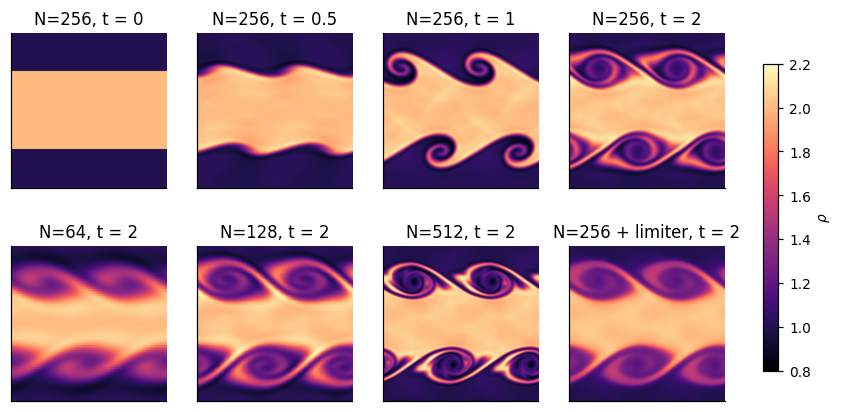

In [5]:
R = pickle.load(open('results.pkl', 'rb'))
if RECOMPUTE:
    for N in (64, 128, 256, 512):
        R[('res', N, False)] = kh_sim.run(N=N, tEnd=2.0, w0=0.1)
    R[('res', 256, True)] = kh_sim.run(N=256, tEnd=2.0, w0=0.1, limiter=True)
    for N in (128, 256, 512):
        R[('lin', N)] = kh_sim.run(N=N, tEnd=1.5, w0=1e-3)

snaps = movie_run['snaps']
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for ax, t in zip(axes[0], [0.0, 0.5, 1.0, 2.0]):
    ax.imshow(snaps[t].T, origin='lower', extent=[0,1,0,1], cmap=CMAP, vmin=VMIN, vmax=VMAX)
    ax.set_title(f'N=256, t = {t:g}')
panels = [(('res', 64, False), 'N=64'), (('res', 128, False), 'N=128'),
          (('res', 512, False), 'N=512'), (('res', 256, True), 'N=256 + limiter')]
for ax, (k, lab) in zip(axes[1], panels):
    im = ax.imshow(R[k]['rho'].T, origin='lower', extent=[0,1,0,1], cmap=CMAP, vmin=VMIN, vmax=VMAX)
    ax.set_title(f'{lab}, t = 2')
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02, label=r'$\rho$')
plt.show()

- **Resolution:** the large-scale billows agree at every $N$, but the fine structure keeps changing. Interfaces get sharper and secondary billows appear at $N = 512$. KH has no pointwise converged answer, because its growth rate $\propto k$, so the smallest resolved scales always grow fastest.
- **Slope limiter:** it suppresses oscillations at sharp jumps but is more diffusive. At $N=256$ with the limiter, the picture looks roughly like $N=128$ without it.

## 5. Quantitative test: linear growth rate
For a sharp, incompressible vortex sheet, linear theory gives

$$\sigma = k\,\Delta U\,\frac{\sqrt{\rho_1\rho_2}}{\rho_1+\rho_2}.$$

Here $k = 4\pi$, $\Delta U = 1$ and $\rho_{1,2} = 1, 2$, which gives $\sigma \approx 5.92$. To stay in the linear regime longer, the runs below use a small seed, $w_0 = 10^{-3}$. I track the amplitude of the $k = 4\pi$ Fourier mode of $v_y$ (maximized over $y$) and fit an exponential over $0.5 \le t \le 1.2$.

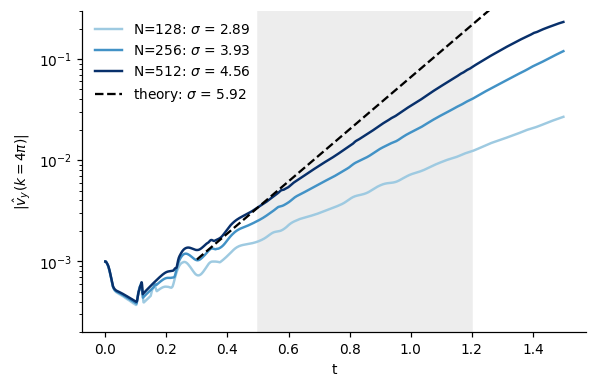

convergence order p = 0.74; extrapolated sigma_inf = 5.49 (93% of theory 5.92)


In [6]:
k, dU, r1, r2 = 4*np.pi, 1.0, 1.0, 2.0
sigma_th = k*dU*np.sqrt(r1*r2)/(r1+r2)
win = (0.5, 1.2)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
sig = {}
for N, c in zip((128, 256, 512), ('#9ecae1', '#4292c6', '#08306b')):
    t, A = R[('lin', N)]['t'], R[('lin', N)]['A']
    m = (t >= win[0]) & (t <= win[1])
    sig[N] = np.polyfit(t[m], np.log(A[m]), 1)[0]
    ax.semilogy(t, A, color=c, lw=1.6, label=fr'N={N}: $\sigma$ = {sig[N]:.2f}')
r512 = R[('lin', 512)]; i0 = np.argmin(abs(r512['t']-0.5)); tt = np.linspace(0.3, 1.5, 50)
ax.semilogy(tt, r512['A'][i0]*np.exp(sigma_th*(tt-0.5)), 'k--', label=fr'theory: $\sigma$ = {sigma_th:.2f}')
ax.axvspan(*win, color='0.93', zorder=0)
ax.set_xlabel('t'); ax.set_ylabel(r'$|\hat v_y(k=4\pi)|$'); ax.set_ylim(2e-4, 0.3)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

# Richardson-style extrapolation  sigma(N) = sigma_inf - C N^-p
s1, s2, s3 = sig[128], sig[256], sig[512]
p = np.log2((s2-s1)/(s3-s2)); s_inf = s3 + (s3-s2)/(2**p - 1)
print(f'convergence order p = {p:.2f}; extrapolated sigma_inf = {s_inf:.2f} '
      f'({100*s_inf/sigma_th:.0f}% of theory {sigma_th:.2f})')

The measured growth rate **converges toward the theoretical value** with resolution, and the extrapolation lands within about 7% of it. The remaining gap is physical and numerical:
- **Numerical diffusion**, mostly from the dissipative Rusanov flux, spreads the initially sharp interface over a few cells. A shear layer of thickness $a$ is stabilized for $ka \gtrsim 1$, so growth is slower than for a perfect vortex sheet.
- **Compressibility** (Mach ≈ 0.3) slightly lowers the growth rate.
- **The seed isn't an exact eigenmode**, hence the dip and sound-wave wiggles for $t \lesssim 0.4$ before clean exponential growth sets in.

## 6. Conservation
Because every flux leaves one cell and enters its neighbour, totals should be conserved to machine precision. Total $x$- and $y$-momentum are zero initially, so I show their absolute change.

In [7]:
print(f"{'run':>16} {'steps':>6} {'dM/M':>10} {'dE/E':>10} {'dPx':>10} {'dPy':>10}")
for key, lab in [(('res',64,False),'N=64'), (('res',128,False),'N=128'), (('res',256,False),'N=256'),
                 (('res',512,False),'N=512'), (('res',256,True),'N=256+limiter')]:
    r = R[key]; d = r['tot1'] - r['tot0']
    print(f"{lab:>16} {r['nstep']:>6} {d[0]/r['tot0'][0]:>10.1e} {d[3]/r['tot0'][3]:>10.1e} {d[1]:>10.1e} {d[2]:>10.1e}")

             run  steps       dM/M       dE/E        dPx        dPy
            N=64    874    0.0e+00    0.0e+00    0.0e+00    3.5e-18
           N=128   1813    0.0e+00   -1.1e-16    0.0e+00    8.7e-19
           N=256   3695    0.0e+00    0.0e+00    0.0e+00    1.1e-17
           N=512   7627    0.0e+00    0.0e+00    0.0e+00   -2.6e-18
   N=256+limiter   3396    0.0e+00    0.0e+00    0.0e+00    8.7e-19
